# Measure individual mobility

**Question.** How far, how often and how predictably does each person move, and which places matter to them?

**You will get** per-person values for range, number of places, visit counts, place-visit entropy, inferred home and work, and ranked place lists, plus population-level distributions of the main ones.

**Prerequisites.** The trajectory table and the idea of a measure per person ([Start with a trajectory](analyze-a-simple-trajectory.md)). In a clean local environment the notebook ran in about 25 seconds (install 11 to 15, download and load 8 to 25 across local runs); Colab was not measured. The run-time table at the end shows the numbers for your own run.

**Data.** [Brightkite](https://snap.stanford.edu/data/loc-brightkite.html), location check-ins from a location-based social network (Stanford SNAP, 2008 to 2010). The full file is about 60 MB; `fastmob.data.load_brightkite` streams it and stops after 300,000 rows, about 4 MB. Users with fewer than 100 check-ins in that window are dropped, which leaves about 306 users and 283,500 check-ins (after also removing placeholder coordinates, see below). Check-ins are voluntary and sparse, so they describe where people chose to check in rather than all their movement.

> **Requires `fastmob` 0.3.4 or newer**, which provides the dataset loaders `fastmob.data.load_geolife` and `load_brightkite` (0.3.3 has them but caches GeoLife files across calls).

In [1]:
import time
from contextlib import contextmanager

_NOTEBOOK_START = time.perf_counter()
PHASES = {}


@contextmanager
def phase(name):
    """Add the wall-clock time of the block to PHASES[name]."""
    start = time.perf_counter()
    try:
        yield
    finally:
        PHASES[name] = PHASES.get(name, 0.0) + time.perf_counter() - start

In [2]:
with phase("setup"):
    get_ipython().run_line_magic("pip", "install -q 'fastmob>=0.3.4' pandas matplotlib")

In [3]:
import fastmob.data

assert hasattr(fastmob.data, "load_geolife") and hasattr(fastmob.data, "load_brightkite"), (
    "This notebook needs fastmob 0.3.4 or newer (older releases lack the dataset loaders or have a loader caching bug)."
)

## Load the data

`load_brightkite` downloads the first rows of the file and returns a trajectory table with `uid`, `datetime`, `lat` and `lng`. We drop users with fewer than 100 check-ins, which are too few for stable per-person measures.

In [4]:
import tempfile
from pathlib import Path

import fastmob
from fastmob.data import load_brightkite

cache_status = "cached (files from an earlier run were reused)" if (Path(tempfile.gettempdir()) / "fastmob_data" / "brightkite").exists() else "cold (nothing cached before this run)"

with phase("download and load"):
    checkins = load_brightkite(max_rows=300_000).to_pandas()

null_island = ((checkins["lat"] == 0) & (checkins["lng"] == 0)) | (checkins["lat"].abs() >= 90)
print(f"dropping {null_island.sum()} check-ins at latitude 0, longitude 0 (a placeholder for 'unknown') or with an impossible latitude")
checkins = checkins[~null_island]
counts = checkins.groupby("uid").size()
checkins = checkins[checkins["uid"].isin(counts[counts >= 100].index)].reset_index(drop=True)
print(len(checkins), "check-ins from", checkins["uid"].nunique(), "users")
checkins.head()

dropping 8327 check-ins at latitude 0, longitude 0 (a placeholder for 'unknown') or with an impossible latitude
283543 check-ins from 306 users


,uid,datetime,lat,lng
0,0,2010-10-17 01:48:53,39.747652,-104.992510
1,0,2010-10-16 06:02:04,39.891383,-105.070814
2,0,2010-10-16 03:48:54,39.891077,-105.068532
3,0,2010-10-14 18:25:51,39.750469,-104.999073
4,0,2010-10-14 00:21:47,39.752713,-104.996337


## Units and assumptions

- Distances are in **kilometres**, waiting times in **seconds**.
- Times are **UTC**. Measures that depend on the hour of day (home, work) treat hours as UTC, so a user in San Francisco has "night" shifted by eight hours. For a real study convert `datetime` to local time first.
- Users are identified by `uid`; without it all rows are treated as one person.
- **Check the data first.** Brightkite contains check-ins at exactly latitude 0, longitude 0 (a point in the Atlantic Ocean), which are placeholders for an unknown location, and a few rows whose latitude is 90 degrees or beyond, which is impossible (the coordinates are swapped or invalid). Left in, they would make some users appear to travel thousands of kilometres. The cell above removes them and reports how many there were.

## How far and how widely: radius of gyration, maximum distance, jump lengths

`radius_of_gyration` is the typical distance of a user's check-ins from their centre of mass; `k_radius_of_gyration` computes it from only the user's *k* most visited places. `maximum_distance` is the largest distance between two *consecutive* check-ins of a user, that is, their longest single jump (not the span between their two most distant places).

In [5]:
with phase("analysis"):
    rg = fastmob.radius_of_gyration(checkins)
    krg = fastmob.k_radius_of_gyration(checkins, k=2)
    max_dist = fastmob.maximum_distance(checkins)

ranges = rg.merge(krg, on="uid").merge(max_dist, on="uid")
ranges.describe().round(1)

,radius_of_gyration,k_radius_of_gyration,maximum_distance
count,306.0,306.0,306.0
mean,1001.4,155.4,5767.7
std,1250.1,897.3,4579.4
min,0.0,0.0,0.0
25%,294.6,1.0,1953.5
50%,699.1,4.2,4152.6
75%,1269.3,11.7,9132.1
max,13434.5,13840.8,16954.2


The median user has a radius of gyration of about 700 km and a maximum distance of about 4,000 km: Brightkite users are spread across the world and many travel between cities or continents, so the distribution is wide and heavy-tailed. `k_radius_of_gyration` with k=2 has a median of only about 4 km, which means that for a typical user the two most visited places lie within a few kilometres of each other; the large overall radius comes from the other, less visited places.

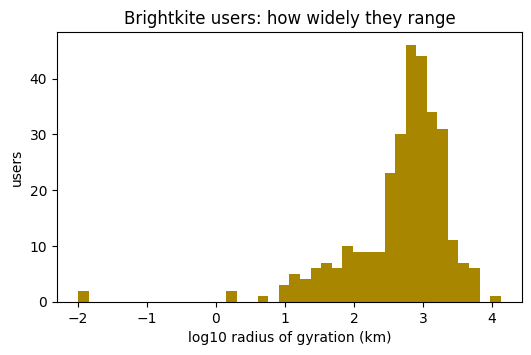

In [6]:
import matplotlib.pyplot as plt
import numpy as np

with phase("plotting"):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(np.log10(rg["radius_of_gyration"].clip(lower=0.01)), bins=40, color="#a98600")
    ax.set_xlabel("log10 radius of gyration (km)")
    ax.set_ylabel("users")
    ax.set_title("Brightkite users: how widely they range")
    plt.show()

Radii span several orders of magnitude, from under a kilometre to over ten thousand, so the histogram uses a log axis. For such data report medians or quantiles rather than means, which the long tail dominates.

`jump_lengths` and `waiting_times` return one list of values per user; `merge=True` returns them as one flat array for pooled distributions.

In [7]:
with phase("analysis"):
    jumps = fastmob.jump_lengths(checkins, merge=True)
    waits = fastmob.waiting_times(checkins, merge=True)

print(f"{len(jumps):,} jumps, median {np.median(jumps):.2f} km, 95th percentile {np.percentile(jumps, 95):.0f} km")
print(f"{len(waits):,} waits, median {np.median(waits) / 3600:.1f} h")

283,237 jumps, median 0.00 km, 95th percentile 58 km
283,237 waits, median 2.0 h


The median jump is 0 km because people often check in repeatedly at the same venue, while the 95th percentile is about 58 km, the same heavy tail seen above. Check-in waits are measured in hours (median about 2) because people check in occasionally.

## How many places: locations, visits and entropy

A *location* here is a distinct coordinate pair. `number_of_locations` counts them, `number_of_visits` counts all check-ins. `uncorrelated_entropy` measures how evenly check-ins are spread over places (0 means one place; higher means more places visited more evenly), and `random_entropy` is the entropy if every place were visited equally often, which is just `log2` of the number of places.

In [8]:
with phase("analysis"):
    places = fastmob.number_of_locations(checkins).merge(fastmob.number_of_visits(checkins), on="uid")
    entropy = fastmob.uncorrelated_entropy(checkins).merge(fastmob.random_entropy(checkins), on="uid")

places.merge(entropy, on="uid").describe().round(2)

,number_of_locations,number_of_visits,uncorrelated_entropy,random_entropy
count,306.00,306.00,306.00,306.00
mean,176.39,926.61,5.04,6.79
std,155.14,737.16,1.81,1.66
min,1.00,105.00,0.00,0.00
25%,65.75,284.25,3.97,6.04
50%,125.50,637.50,5.40,6.97
75%,235.75,1669.00,6.39,7.88
max,771.00,2100.00,8.80,9.59


The average user has about 176 distinct places for about 927 visits, and the uncorrelated entropy (about 5.0 bits) sits below the random entropy (about 6.8 bits): visits concentrate on a few favourite places instead of spreading evenly. The gap between the two columns is a simple measure of how routine someone's behaviour is.

## Which places matter: frequency and recency ranks

`location_frequency` returns every place of every user with the share of visits it receives; `frequency_rank` orders them by visits and `recency_rank` by how recently they were last visited. They return one row per user and place.

In [9]:
with phase("analysis"):
    top = fastmob.frequency_rank(checkins)
    freq = fastmob.location_frequency(checkins)
    recent = fastmob.recency_rank(checkins)

first_user = top["uid"].iloc[0]
print("user", first_user, "- most visited places and their share of visits")
top[top["uid"] == first_user].merge(freq, on=["uid", "lat", "lng"]).head(5)

user 0 - most visited places and their share of visits


,uid,lat,lng,frequency_rank,location_frequency
0,0,39.762146,-104.982480,1,0.102638
1,0,39.891077,-105.068532,2,0.065707
2,0,39.739154,-104.984703,3,0.060432
3,0,39.891586,-105.068463,4,0.034532
4,0,39.827022,-105.143191,5,0.025420


This user's most visited place receives about 10% of their visits, followed by about 7% and 6%. `recency_rank` answers a different question: which place was visited last, independent of how often. Here are the same user's most recently visited places.

In [10]:
recent[recent["uid"] == first_user].head(5)

,uid,lat,lng,recency_rank
0,0,39.747652,-104.992510,1
1,0,39.891383,-105.070814,2
2,0,39.891077,-105.068532,3
3,0,39.750469,-104.999073,4
4,0,39.752713,-104.996337,5


Rank 1 is the place of the user's latest check-in, rank 2 the next most recently visited different place, and so on. The most visited place from the previous table is not among the five most recent: a favourite place can be stale, which is why the two ranks answer different questions.

## Home and work

`home_location` is the place a user visits most between `start_night` and `end_night` hours (default 22 to 7); if a user has no check-ins in that window it falls back to their most visited place overall. `work_location` is the most visited place between 8 and 18 on weekdays (Monday to Friday). `max_distance_from_home` is the farthest check-in from the inferred home. Remember that the hours, and so the weekdays, are UTC.

In [11]:
with phase("analysis"):
    homes = fastmob.home_location(checkins)
    works = fastmob.work_location(checkins)
    away = fastmob.max_distance_from_home(checkins)

hours = checkins["datetime"].dt.hour
night_users = checkins.loc[(hours >= 22) | (hours < 7), "uid"].nunique()
print(len(homes), "users with an inferred home, of which", night_users, "have any check-in between 22:00 and 07:00 UTC;", len(works), "with a work location")
homes.merge(away, on="uid").head()

306 users with an inferred home, of which 306 have any check-in between 22:00 and 07:00 UTC; 305 with a work location


,uid,lat,lng,max_distance_from_home
0,0,39.891077,-105.068532,8107.017192
1,1,37.630490,-122.411084,309.111589
2,2,39.739154,-104.984703,8016.409740
3,3,37.748170,-122.459192,4343.488499
4,4,60.180171,24.949728,15512.810134


Every user has at least one check-in in the UTC night window, so the fallback to the most visited place was not needed here. But the window is **UTC**, not each user's local night: for a San Francisco user, 22:00 to 07:00 UTC is 14:00 to 23:00 local time, so their inferred "home" mostly reflects afternoon and evening check-ins. Convert `datetime` to local time before inferring home or work. Either way, a home inferred from social check-ins is a guess about where someone is at night, not a verified address.

## A user's mobility network

`individual_mobility_network` turns a user's check-ins into a directed network whose nodes are places and whose edges count the trips between consecutive places.

In [12]:
with phase("analysis"):
    network = fastmob.individual_mobility_network(checkins)

network.groupby("uid")["n_trips"].agg(edges="size", trips="sum").describe().round(1)

,edges,trips
count,304.0,304.0
mean,322.2,438.7
std,302.4,409.0
min,2.0,2.0
25%,107.8,134.0
50%,215.5,269.0
75%,443.5,627.8
max,1663.0,1999.0


The median user has about 216 distinct place-to-place connections for about 269 trips, so most connections are travelled only once or twice: a few routine links plus many one-off trips.

## Interpretation and limits

- The numbers describe check-in behaviour. Someone who never checks in at home has no home here.
- Placeholder (0, 0) coordinates and impossible latitudes were removed; other wrong coordinates may remain.
- Only 300,000 of 4.7 million rows were read, in the file's own order. The first users are not a random sample.
- Distances are straight lines between check-ins; entropies treat each exact coordinate as a place, so GPS noise would inflate them. Cluster stops into places first ([Clean noisy GPS data and find stops](clean-and-detect-stops.md)).
- Time-of-day measures depend on the UTC assumption above.

## Next steps

- Population-level summaries, such as visits per location: [Measure people and populations](individual-and-collective-measures.md).
- Fit a model to the jump-length distribution: [Compare mobility laws](compare-to-mobility-laws.md).

## Related API

[`radius_of_gyration`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.radius_of_gyration) ·
[`k_radius_of_gyration`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.k_radius_of_gyration) ·
[`maximum_distance`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.maximum_distance) ·
[`jump_lengths`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.jump_lengths) ·
[`waiting_times`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.waiting_times) ·
[`number_of_locations`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.number_of_locations) ·
[`number_of_visits`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.number_of_visits) ·
[`uncorrelated_entropy`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.uncorrelated_entropy) ·
[`random_entropy`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.random_entropy) ·
[`frequency_rank`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.frequency_rank) ·
[`location_frequency`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.location_frequency) ·
[`recency_rank`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.recency_rank) ·
[`home_location`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.home_location) ·
[`work_location`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.work_location) ·
[`max_distance_from_home`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.max_distance_from_home) ·
[`individual_mobility_network`](https://gefgu.github.io/fastmob/reference/measures/individual/#fastmob.measures.individual.individual_mobility_network)

## Run time

Measured by the notebook's own wall clock.

In [13]:
import datetime
import platform
from importlib.metadata import version

import pandas as pd

total = time.perf_counter() - _NOTEBOOK_START
measured = sum(PHASES.values())
timing = pd.DataFrame({"seconds": {**PHASES, "untimed cells and display": total - measured, "total notebook runtime": total}}).round(2)
print(timing.to_string())
print()
print("Download:", 'about 4 MB of the 60 MB Brightkite file (stream stopped after 300,000 rows)')
print("Cache:", cache_status)
print("Rows analysed:", len(checkins))
print("Environment: Python", platform.python_version(), "| fastmob", version("fastmob"), "| pandas", version("pandas"),
      "| measured", datetime.datetime.now(datetime.timezone.utc).date().isoformat())

                           seconds
setup                        20.39
download and load            19.31
analysis                     24.98
plotting                      0.45
untimed cells and display     3.10
total notebook runtime       68.23

Download: about 4 MB of the 60 MB Brightkite file (stream stopped after 300,000 rows)
Cache: cold (nothing cached before this run)
Rows analysed: 283543
Environment: Python 3.10.12 | fastmob 0.3.4 | pandas 2.3.3 | measured 2026-10-27
